# System model, controller, and a fresh simulation

**Author: Mohammad ALbaraj**

[Notebook index](README.md) · [Main project](../README.md)

Run cells from top to bottom. Saved results and fresh examples are labeled separately. Scientific source modules remain the authoritative implementation.


In [1]:
from pathlib import Path
import sys, json, csv
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Code

# Works when launched from the repository root or any notebook subdirectory.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'CITATION.cff').exists() and (p / 'all work').is_dir())
if str(ROOT / 'notebooks') not in sys.path:
    sys.path.insert(0, str(ROOT / 'notebooks'))
from notebook_support import (METHODS, ORIGINAL, NOMINAL, ROBUST, study, load_json,
    load_csv, show_table, show_source, source_index, load_runs, fitness_summary,
    convergence_plot, validation_rows, validation_summary, figures, file_links,
    show_figures, gallery, isolated_python, demo_source)
plt.rcParams.update({'figure.dpi': 100, 'font.size': 10})
print('Project loaded. Default cells do not launch full optimization campaigns.')


Project loaded. Default cells do not launch full optimization campaigns.


## Signal flow

```text
Roll/pitch angle commands -> outer proportional loops -> rate references
Yaw-rate command -------------------------------------> yaw PI
Rate errors -> discrete roll/pitch controllers -> torque commands
Torque commands + throttle -> saturated mixer -> motor dynamics
Motor speeds -> nonlinear moments -> body rates/quaternion -> measured attitude
```

The 11-state attitude subsystem contains quaternion (4), body rates (3), and motor speeds (4). Translation does not feed rotational torque in this source model. A separate `full_rhs` provides a 17-state extension, but position and altitude are not optimized here. Controller timing is 1 ms, mixer timing 4 ms; these are source assumptions, not compiled-Simulink or hardware validation.


In [2]:
model_path=study('GA')/'model.py'
show_source(model_path, 'rhs')


def rhs(x, u, plant, disturbance, out):
    a,b,c,d = x[0],x[1],x[2],x[3]
    p,q,r = x[4],x[5],x[6]
    w1,w2,w3,w4 = x[7],x[8],x[9],x[10]
    Jx,Jy,Jz,R,Ct,Cm = plant[:6]
    arm = math.sqrt(.5)*R*Ct
    Mx = arm*(-w1*w1+w2*w2+w3*w3-w4*w4)
    My = arm*(w1*w1-w2*w2+w3*w3-w4*w4)
    Mz = Cm*(w1*w1+w2*w2-w3*w3-w4*w4)
    spin = w1+w2-w3-w4
    # Source Add1 adds propeller, aerodynamic and gyroscopic moments.
    Mx += -plant[6]*p*abs(p) + plant[9]*q*spin + disturbance[0]
    My += -plant[7]*q*abs(q) - plant[9]*p*spin + disturbance[1]
    Mz += -plant[8]*r*abs(r) + disturbance[2]
    out[0] = -.5*(p*b+q*c+r*d)
    out[1] = .5*(p*a+r*c-q*d)
    out[2] = .5*(q*a-r*b+p*d)
    out[3] = .5*(r*a+q*b-p*c)
    out[4] = (Mx-(Jz-Jy)*q*r)/Jx
    out[5] = (My-(Jx-Jz)*p*r)/Jy
    out[6] = (Mz-(Jy-Jx)*p*q)/Jz
    for j in range(4):
        # Deliberately preserve the source's negative low-throttle target.
        out[7+j] = (plant[11]*u[j]+plant[12]-x[7+j])/plant[10]

## Discrete controller coefficients
Roll/pitch use the fixed pole 0.9997. Equivalent Kp/Ki labels must be converted with the source formula; yaw derivative gain is zero.


In [3]:
show_source(model_path, 'coefficients')
show_source(model_path, 'baseline')


def coefficients(gains, controller_dt=.001, pole=POLE):
    return {axis: {'numerator': [float(gains[i+1]+gains[i+2]*controller_dt),
                                float(-pole*gains[i+1])],
                   'denominator': [1.0, -pole]}
            for axis, i in [('roll', 0), ('pitch', 3)]}

def baseline(controller_dt=.001):
    # Exactly reconstruct b=[.03248,-.03223], a=[1,-.9997].
    ki = (.03248 - BASE_KP) / controller_dt
    return np.array([5.0119, BASE_KP, ki, 5.0119, BASE_KP, ki, .5, .01])

## Complete sampled simulation implementation
RK4 propagates the nonlinear plant between sampled control/mixer updates. The source below also defines trace columns, metrics, constraints, and early-abort behavior.


In [4]:
show_source(model_path, 'simulate')


def simulate(gains, target, plant, throttle, dt, control_dt, mixer_dt,
             pre_step, horizon, initial_motors_zero=False, store=False,
             pulse_axis=-1, pulse_amplitude=0., pulse_start=1.2, pulse_end=1.3,
             noise_amplitude=0., pole=POLE, band=.02, final_hold=.25, inner=False):
    """RK4 plant with sampled controller and held mixer outputs.

    Returns metrics[3,10], diagnostics[7], trace[:,36].
    Metrics: rise,settle,overshoot,final_abs_error,IAE,ITAE,peak_abs,
             reached_90,settled,final_signed_error. Ratios normalize by
             command amplitude; inactive axes by 5 deg / 30 deg/s.
    Trace: t,roll,pitch,yaw,p,q,r,refs(3),rate_refs(3),raw_control(3),
           control(3),raw_motor(4),motor(4),min_motor_speed,motor_speed(4),quat(4).
    """
    nc = int(round(control_dt/dt)); nm = int(round(mixer_dt/dt))
    steps = int(round((pre_step+horizon)/dt))
    start = int(round(pre_step/dt))
    x = np.zeros(11); x[0] = 1.
    if not initial_motors_zero:
        x[7:] = plant[11]*throttle+plant[12]
    k1=np.empty(11); k2=np.empty(11); k3=np.empty(11); k4=np.empty(11)
    temp=np.empty(11); dist=np.zeros(3)
    ref=np.zeros(3); desired_rate=np.zeros(3)
    prev_error=np.zeros(2); prev_output=np.zeros(2)
    raw=np.zeros(3); ctrl=np.zeros(3)
    motors=np.full(4, throttle); rawmot=np.full(4, throttle)
    integral_yaw=0.
    metrics=np.zeros((3,10)); diag=np.zeros(7)
    t10=np.full(3,-1.); t90=np.full(3,-1.); lastoutside=np.full(3,-dt)
    peak=np.zeros(3); finalsum=np.zeros(3); tail_count=0
    denom=np.empty(3); active=np.zeros(3, dtype=np.bool_)
    for j in range(3):
        active[j] = abs(target[j]) > 1e-12
        denom[j] = abs(target[j]) if active[j] else (5*math.pi/180 if j<2 else 30*math.pi/180)
    trace=np.zeros((steps+1 if store else 1,36))
    count=0; clipcount=0; ctrlclip=0; rateclip=0; effort=0.; maxbank=0.
    minomega=1e9; failed=False
    for n in range(steps+1):
        t=n*dt
        roll,pitch,yaw=euler(x)
        if n>=start:
            ref[:] = target
        if n % nc == 0:
            # Fixed deterministic measurement perturbations used only in holdout.
            er0 = ref[0]-roll-noise_amplitude*math.sin(61*t)
            er1 = ref[1]-pitch-noise_amplitude*math.sin(73*t+.3)
            rp0 = gains[0]*er0; rp1 = gains[3]*er1
            if inner:
                rp0=ref[0]; rp1=ref[1]
            desired_rate[0]=min(220.,max(-220.,rp0))
            desired_rate[1]=min(220.,max(-220.,rp1))
            desired_rate[2]=ref[2]
            for j in range(2):
                idx=3*j
                error=desired_rate[j]-x[4+j]-noise_amplitude*math.sin(89*t+j)
                b0=gains[idx+1]+gains[idx+2]*control_dt
                b1=-pole*gains[idx+1]
                raw[j]=pole*prev_output[j]+b0*error+b1*prev_error[j]
                prev_error[j]=error
                prev_output[j]=raw[j]  # No invented anti-windup.
                ctrl[j]=min(1.,max(-1.,raw[j]))
            ey=ref[2]-x[6]-noise_amplitude*math.sin(97*t)
            # Source forward-Euler integrator outputs its OLD state this sample.
            raw[2]=gains[6]*ey+integral_yaw
            integral_yaw=min(.2,max(-.2,integral_yaw+control_dt*gains[7]*ey))
            ctrl[2]=min(.5,max(-.5,raw[2]))
        if n % nm == 0:
            R,P,Y=ctrl[0],ctrl[1],ctrl[2]
            rawmot[0]=throttle-R+P+Y
            rawmot[1]=throttle+R-P+Y
            rawmot[2]=throttle+R+P-Y
            rawmot[3]=throttle-R-P-Y
            for j in range(4):
                motors[j]=min(1.,max(0.,rawmot[j]))
        maxbank=max(maxbank,abs(roll),abs(pitch))
        minomega=min(minomega,x[7],x[8],x[9],x[10])
        if n>=start:
            tau=t-pre_step
            count+=1
            clipped=False
            for j in range(4):
                if rawmot[j]<-1e-10 or rawmot[j]>1+1e-10: clipped=True
                effort += (motors[j]-throttle)**2 / 4
            if clipped: clipcount+=1
            if abs(ra

## Fresh example: baseline versus archived CSO gains
This executes only two roll-step simulations using the original source in an isolated Python process. It is not a fresh optimization or a rerun of the full archive. Numba may take several seconds on the first call. Change the target in the source string to try another scenario.


In [5]:
simulation_source = "import json, os\nfrom pathlib import Path\nimport numpy as np\nfrom model import baseline, run, coefficients\nfrom study import evaluate\ncfg=json.loads(Path('config.json').read_text())\nsaved=json.loads(Path('results/best_gains.json').read_text())\ngains=np.array([saved['gains'][p['name']] for p in cfg['parameters']])\nscenario={'name':'notebook_roll_20','target':[20,0,0]}\nout=Path(os.environ['PID_NOTEBOOK_OUTPUT'])\nsummary=[]\nfor label,g in [('baseline',baseline()),('saved_CSO',gains)]:\n    metrics,diagnostics,trace=run(g,scenario,cfg,store=True)\n    np.savez_compressed(out/(label+'_simulation.npz'),metrics=metrics,diagnostics=diagnostics,trace=trace)\n    summary.append({'controller':label,'scenario':'roll 20 degrees','rise_s':float(metrics[0,0]),'settling_s':float(metrics[0,1]),'overshoot_pct':float(metrics[0,2]*100),'fitness':float(evaluate(g,[scenario],cfg))})\n(out/'simulation_summary.json').write_text(json.dumps(summary))\n(out/'coefficients.json').write_text(json.dumps(coefficients(gains)))\nprint('Completed two fresh single-scenario simulations; archived results were not changed.')\n"
output = isolated_python("CSO", simulation_source)
show_table(load_json(output/"simulation_summary.json"))


Completed two fresh single-scenario simulations; archived results were not changed.


controller,scenario,rise_s,settling_s,overshoot_pct,fitness
baseline,roll 20 degrees,0.189,0.7400000000000001,0.0,0.13241872031419266
saved_CSO,roll 20 degrees,0.07799999999999999,0.31,8.573718364492766,0.05480010542918321


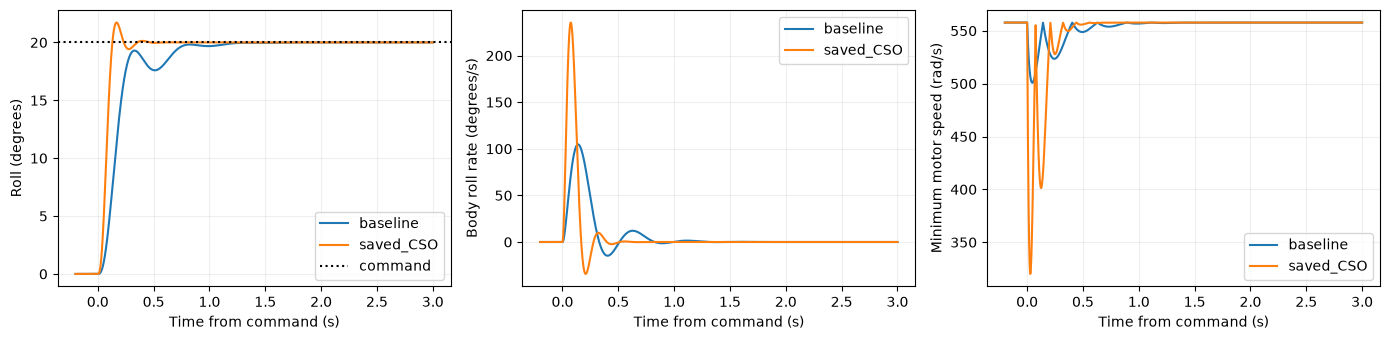

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for label in ['baseline','saved_CSO']:
    with np.load(output/(label+'_simulation.npz'), allow_pickle=False) as data:
        trace=data['trace']; t=trace[:,0]-0.2
        axes[0].plot(t,np.rad2deg(trace[:,1]),label=label)
        axes[1].plot(t,np.rad2deg(trace[:,4]),label=label)
        axes[2].plot(t,trace[:,27],label=label)
axes[0].axhline(20,color='black',linestyle=':',label='command')
for ax,y in zip(axes,['Roll (degrees)','Body roll rate (degrees/s)','Minimum motor speed (rad/s)']):
    ax.set(xlabel='Time from command (s)',ylabel=y); ax.grid(alpha=.2); ax.legend()
fig.tight_layout(); plt.show(); plt.close(fig)


## Source model files and full-state equations
SLX files are MATLAB/Simulink models, not executable Python notebooks. Their readable XML and initialization scripts are included. The notebook displays them as source references; it does not claim to execute Simulink.


In [7]:
file_links(sorted((study('GA')/'source').iterdir()), 'MATLAB/Simulink source')
show_source(model_path,'full_rhs')


### MATLAB/Simulink source
- [all work/pid using ga/source/AttitudeControl_Sim.slx](../all%20work/pid%20using%20ga/source/AttitudeControl_Sim.slx)
- [all work/pid using ga/source/bddefaults.xml](../all%20work/pid%20using%20ga/source/bddefaults.xml)
- [all work/pid using ga/source/blockdiagram.xml](../all%20work/pid%20using%20ga/source/blockdiagram.xml)
- [all work/pid using ga/source/configSet0.xml](../all%20work/pid%20using%20ga/source/configSet0.xml)
- [all work/pid using ga/source/Init.m](../all%20work/pid%20using%20ga/source/Init.m)
- [all work/pid using ga/source/Init_control.m](../all%20work/pid%20using%20ga/source/Init_control.m)
- [all work/pid using ga/source/inventory.json](../all%20work/pid%20using%20ga/source/inventory.json)
- [all work/pid using ga/source/stateflow.xml](../all%20work/pid%20using%20ga/source/stateflow.xml)

def full_rhs(state, motor_commands, plant=NOMINAL, mass=1.4, gravity=9.8, drag=.055):
    """Complete 17-state source equations, available for separate trajectory work.

    State: rotation/motors (11), body velocity (3), earth position NED (3).
    This confirms mathematically why translation is excluded from GA fitness.
    """
    out=np.zeros(17)
    rhs(state[:11], np.asarray(motor_commands), plant, np.zeros(3), out[:11])
    R=rotation_matrix(state[:4]); vb=state[11:14]
    fb=R.T@np.array([0.,0.,mass*gravity])-.5*drag*vb*np.abs(vb)
    fb[2]-=plant[4]*np.sum(state[7:11]**2)
    out[11:14]=fb/mass-np.cross(state[4:7],vb)
    out[14:17]=R@vb
    return out